# Acoustic Spectra → Reynolds: Compact GRU

Repository-ready notebook. Data preparation, model training, evaluation, and inference live in `src/spectral_to_reynolds`. **All paths and experiment settings come from root `config.json`.**

Training and validation include leak rows, as in the original notebook. The reported metrics are validation metrics; the 16-model grid uses the same validation run for model selection.

In [9]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "config.json").exists():
    ROOT = ROOT.parent
if not (ROOT / "config.json").exists():
    raise FileNotFoundError("Run this notebook from the repository root or notebooks/ directory")
sys.path.insert(0, str(ROOT / "src"))
from spectral_to_reynolds.pipeline import load_config, load_data, run_search, load_saved_model, predict_saved

cfg = load_config(ROOT)
print("Repository:", ROOT)
print("Data directory:", ROOT / cfg["data_dir"])

Repository: /home/ubuntu/notebooks/Leak_Detection
Data directory: /home/ubuntu/notebooks/Leak_Detection/data/2026-03-04


## Input data

Use the eight CSV files specified by the run IDs and probe names in the configuration.

In [10]:
train_run, val_run, Xw_train, y_train, Xw_val, y_val = load_data(ROOT, cfg)
print("Training:", train_run["iteration"], Xw_train.shape)
print("Validation:", val_run["iteration"], Xw_val.shape)

Training: 1211_1 (10762, 40, 4, 27)
Validation: 1212_1 (10762, 40, 4, 27)


## Model search

Run the configured compact-GRU grid. The existing LSTM and standard GRU results are reference values, not retrained. The selected production candidate is **e24/h16** even if another grid point has a slightly lower RMSE.

In [11]:
search_df, all_results, selected_model_path = run_search(ROOT, cfg, Xw_train, y_train, Xw_val, y_val)
display(all_results.sort_values("RMSE"))
print("Saved selected model:", selected_model_path)

Epoch 001 | train=0.27237 | val=0.26123
Epoch 010 | train=0.05474 | val=0.07810
Epoch 020 | train=0.05067 | val=0.09386
Early stopping at 24
Best epoch: 9 | parameters: 2,097 | time: 68.3s
Epoch 001 | train=0.28180 | val=0.25918
Epoch 010 | train=0.05695 | val=0.07600
Epoch 020 | train=0.05264 | val=0.06311
Early stopping at 29
Best epoch: 14 | parameters: 3,497 | time: 96.0s
Epoch 001 | train=0.26461 | val=0.25187
Epoch 010 | train=0.05418 | val=0.08612
Epoch 020 | train=0.05016 | val=0.07059
Early stopping at 24
Best epoch: 9 | parameters: 5,281 | time: 90.6s
Epoch 001 | train=0.24581 | val=0.17310
Epoch 010 | train=0.05340 | val=0.06894
Epoch 020 | train=0.04843 | val=0.08547
Early stopping at 26
Best epoch: 11 | parameters: 10,001 | time: 120.6s
Epoch 001 | train=0.23434 | val=0.19442
Epoch 010 | train=0.05283 | val=0.05696
Epoch 020 | train=0.04942 | val=0.06173
Early stopping at 29
Best epoch: 14 | parameters: 2,705 | time: 92.7s
Epoch 001 | train=0.27340 | val=0.25429
Epoch 010 

,Model,Embed_dim,Hidden_dim,MAE,RMSE,R2,Train_seconds,Parameters,MAE_vs_LSTM_%,RMSE_vs_LSTM_%,Param_ratio_vs_LSTM
3,GRU e16/h24,16.0,24.0,7.845769,11.914334,0.942096,96.014450,3497,-4.059207,-2.150509,0.099525
6,GRU e24/h16,24.0,16.0,7.777004,11.999599,0.941264,92.660339,2705,-4.900091,-1.450245,0.076984
0,LSTM reference,NaN,NaN,8.177720,12.176184,0.939523,343.343762,35137,0.000000,0.000000,1.000000
10,GRU e32/h16,32.0,16.0,8.389971,12.500414,0.936259,114.537595,3313,2.595476,2.662825,0.094288
1,GRU 64/64 reference,64.0,64.0,8.540041,12.597369,0.935267,161.645009,26817,4.430587,3.459089,0.763213
5,GRU e16/h48,16.0,48.0,8.670309,12.599161,0.935248,120.592430,10001,6.023550,3.473807,0.284629
13,GRU e32/h48,32.0,48.0,8.376507,12.782051,0.933355,91.003860,12753,2.430834,4.975837,0.362951
8,GRU e24/h32,24.0,32.0,8.465461,12.798990,0.933178,84.952032,6273,3.518594,5.114948,0.178530
4,GRU e16/h32,16.0,32.0,9.656252,12.858560,0.932555,90.606808,5281,18.080002,5.604184,0.150297
7,GRU e24/h24,24.0,24.0,8.936881,12.936257,0.931737,115.620313,4297,9.283285,6.242296,0.122293


Saved selected model: /home/ubuntu/notebooks/Leak_Detection/models/compact_gru_e24_h16_1211_1_to_1212_1.pt


## Models meeting the acceptance criteria

In [12]:
acceptable = search_df[(search_df.MAE < cfg["mae_threshold"]) & (search_df.RMSE < cfg["rmse_threshold"]) & (search_df.R2 > cfg["r2_threshold"])].sort_values(["Parameters","RMSE"])
display(acceptable)

,Model,MAE,RMSE,R2,Train_seconds,Parameters,Embed_dim,Hidden_dim
4,GRU e24/h16,7.777004,11.999599,0.941264,92.660339,2705,24,16
8,GRU e32/h16,8.389971,12.500414,0.936259,114.537595,3313,32,16
1,GRU e16/h24,7.845769,11.914334,0.942096,96.014450,3497,16,24
5,GRU e24/h24,8.936881,12.936257,0.931737,115.620313,4297,24,24
6,GRU e24/h32,8.465461,12.798990,0.933178,84.952032,6273,24,32
3,GRU e16/h48,8.670309,12.599161,0.935248,120.592430,10001,16,48
11,GRU e32/h48,8.376507,12.782051,0.933355,91.003860,12753,32,48


## Complexity versus validation error

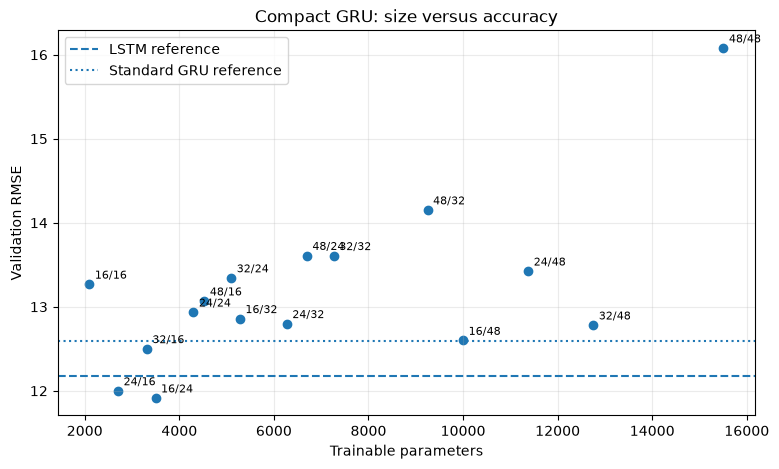

In [13]:
fig, ax = plt.subplots(figsize=(9,5))
ax.scatter(search_df.Parameters,search_df.RMSE)
for _,r in search_df.iterrows():
    ax.annotate(f"{int(r.Embed_dim)}/{int(r.Hidden_dim)}",(r.Parameters,r.RMSE),xytext=(4,4),textcoords="offset points",fontsize=8)
ax.axhline(12.176184,linestyle="--",label="LSTM reference")
ax.axhline(12.597369,linestyle=":",label="Standard GRU reference")
ax.set(xlabel="Trainable parameters",ylabel="Validation RMSE",title="Compact GRU: size versus accuracy")
ax.legend();ax.grid(alpha=.25);plt.show()

## Load the selected model for inference

The loader works with an existing checkpoint as well; retraining is not required for inference.

In [14]:
model, checkpoint = load_saved_model(selected_model_path)
print("Loaded:", selected_model_path.name)
print("Dimensions:", checkpoint["embed_dim"], checkpoint["hidden_dim"])
print("Predictions (physical Reynolds units):", predict_saved(selected_model_path, Xw_val[:5]))

Loaded: compact_gru_e24_h16_1211_1_to_1212_1.pt
Dimensions: 24 16
Predictions (physical Reynolds units): [17.508562 17.133522 16.949406 17.537695 17.866703]


## Interpretation

The Compact GRU uses a 40-step history of acoustic measurements from four probes to predict the current Reynolds number. In the cross-experiment benchmark (training on 1211_1, validation on 1212_1), the selected e24/h16 model achieved MAE = 7.777, RMSE = 12.000, and R² = 0.9413, with only 2,705 parameters and approximately 93 seconds of training. These results should be validated on additional experimental runs to establish generalizability.
